# How I watch soccer

When I watch soccer, I'm invested in the outcome. I live in Louisville and adore our club, Racing. I want my team to do well, ideally to make it to the NWSL playoffs for the first time.

That emotional investment can be challenging. It's obviously easiest for any viewer when the team we're supporting wins. When that doesn't happen, it's easiest when I can anticipate the outcome---if we have a bad run of form and then find ourselves losing to one of the better teams, that makes sense. But it's brutal to be emotionally invested in a team, to have high expectations, and to feel the dissappointment of a surprise poor performance.

So, how do I watch soccer? More than anything, I try to understand how it works at a high level. Nothing too complicated, things like: How can we tell a good team from a bad one? What makes a team likely to win future games? What makes a team's performance during a game good or bad?


In [1]:
from itscalledsoccer.client import AmericanSoccerAnalysis
from plotnine import *
from colour import Color
import numpy as np
import pandas as pd

import numpy as np
from collections import defaultdict

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

asa_client = AmericanSoccerAnalysis()
from sophso import *

In [2]:
# games_df = asa_client.get_games(leagues="nwsl", seasons=["2025"])

# shots_df = decorate_game_ids(
#     decorate_team_ids(
#         decorate_player_ids(
#             asa_client._get_stats(
#                 game_id=games_df.game_id.to_list(),
#                 type="shots",
#                 entity="games",
#                 leagues="nwsl",
#             )
#         )
#     )
# )

# shots_df.date_time_utc = pd.to_datetime(shots_df.date_time_utc)
# shots_df["year"] = shots_df.date_time_utc.dt.year

# shots_df.T

In [3]:
# shots_df.groupby("pattern_of_play").goal.sum()

In [4]:
# pattern_totals_df = shots_df.groupby("pattern_of_play").goal.sum().reset_index()

# pattern_totals_df = pd.concat(
#     [
#         pattern_totals_df,
#         pd.DataFrame([("Own Goal", 19)], columns=pattern_totals_df.columns),
#     ],
#     ignore_index=True,
# )

# pattern_totals_df["percent"] = pattern_totals_df.goal / pattern_totals_df.goal.sum()

# pattern_totals_df

In [5]:
games_df = decorate_game_ids(
    decorate_team_ids(
        asa_client.get_team_xgoals(
            leagues="nwsl", season_name="2025", split_by_games=True
        )
    )
).sort_values("game_desc")

games_df.T

,223,12,37,7,64,11,259,25,185,2,...,155,334,264,135,119,149,80,133,148,172
team_id,KPqjw8PQ6v,315VnJ759x,4JMAk47qKg,315VnJ759x,4wM4rZdqjB,315VnJ759x,kRQa8JOqKZ,315VnJ759x,eV5DR6YQKn,315VnJ759x,...,aDQ0lzvQEv,XVqKeVKM01,Pk5LeeNqOW,aDQ0lzvQEv,7VqG1lYMvW,aDQ0lzvQEv,7vQ7BBzqD1,aDQ0lzvQEv,aDQ0lzvQEv,eV5D2w9QKn
game_id,gpMOpdO25z,gpMOpdO25z,eV5Dpo0A5K,eV5Dpo0A5K,gOMnALRXQw,gOMnALRXQw,xW5pbzxdQg,xW5pbzxdQg,4wM4bRykqj,4wM4bRykqj,...,p6qbjWX6q0,p6qbjWX6q0,2vQ1bDLKMr,2vQ1bDLKMr,KXMeZ67x56,KXMeZ67x56,2lqRpdk0Mr,2lqRpdk0Mr,KPqjj9oRq6,KPqjj9oRq6
shots_for,8,13,10,20,22,8,17,12,12,8,...,13,11,10,17,8,22,6,16,29,9
shots_against,13,8,20,10,8,22,12,17,8,12,...,11,13,17,10,22,8,16,6,9,29
goals_for,2,1,2,2,2,0,0,2,0,2,...,1,2,1,2,1,2,0,2,3,2
goals_against,1,2,2,2,0,2,2,0,2,0,...,2,1,2,1,2,1,2,0,2,3
goal_difference,1,-1,0,0,2,-2,-2,2,-2,2,...,-1,1,-1,1,-1,1,-2,2,1,-1
xgoals_for,1.5551,1.3732,1.5002,2.5897,3.8232,0.3425,1.2215,1.4903,0.9705,0.4782,...,0.933,1.5326,1.0854,2.1914,0.9076,2.7464,0.7668,1.3248,3.7912,0.8612
xgoals_against,1.3732,1.5551,2.5897,1.5002,0.3425,3.8232,1.4903,1.2215,0.4782,0.9705,...,1.5326,0.933,2.1914,1.0854,2.7464,0.9076,1.3248,0.7668,0.8612,3.7912
xgoal_difference,0.182,-0.182,-1.0895,1.0895,3.4807,-3.4807,-0.2687,0.2687,0.4923,-0.4923,...,-0.5996,0.5996,-1.106,1.106,-1.8388,1.8388,-0.5579,0.5579,2.93,-2.93


In [6]:
def get_games_single_season(leagues="nwsl", seasons="2024"):
    games_df = asa_client.get_games(leagues=leagues, seasons=seasons)

    gxg_df = asa_client.get_team_xgoals(
        leagues=leagues,
        season_name=seasons,
        split_by_games=True,
        shot_pattern=[
            "Set piece",
            "Corner",
            "Free kick",
            # "Penalty",
            "Fastbreak",
            "Regular",
        ],
    )

    games_df = pd.concat(
        [
            games_df[
                ["home_team_id", "game_id", "home_score", "away_score", "season_name"]
            ].rename(
                columns={
                    "home_team_id": "team_id",
                    "home_score": "score_for",
                    "away_score": "score_against",
                }
            ),
            games_df[
                ["away_team_id", "game_id", "home_score", "away_score", "season_name"]
            ].rename(
                columns={
                    "away_team_id": "team_id",
                    "home_score": "score_against",
                    "away_score": "score_for",
                }
            ),
        ]
    )

    gxg_df = gxg_df.merge(
        games_df,
        on=["game_id", "team_id"],
        how="left",
    )

    return decorate_game_ids(decorate_team_ids(gxg_df))


def get_games(leagues="nwsl", seasons="2024"):

    if isinstance(seasons, list):

        games_list = []
        for s in seasons:
            print(f"loading games for season: {s}")
            games_list.append(get_games_single_season(leagues=leagues, seasons=s))

        games_df = pd.concat(games_list, ignore_index=True)
    else:
        games_df = get_games_single_season(leagues=leagues, seasons=seasons)

    return games_df

In [7]:
def get_shots_single_season(leagues="nwsl", season="2024"):
    games_df = asa_client.get_games(leagues=leagues, seasons=season)

    shots_df = asa_client._get_stats(
        game_id=games_df.game_id.to_list(), type="shots", entity="games", leagues="nwsl"
    )

    shots_df["season"] = season

    return shots_df


def get_shots(leagues="nwsl", seasons="2024"):

    if isinstance(seasons, list):

        shots_list = []
        for s in seasons:
            print(f"loading shots for season: {s}")
            shots_list.append(
                decorate_game_ids(
                    decorate_team_ids(
                        decorate_player_ids(
                            get_shots_single_season(leagues=leagues, season=s)
                        )
                    )
                )
            )

        shots_df = pd.concat(shots_list, ignore_index=True)
    else:
        shots_df = get_shots_single_season(leagues=leagues, season=seasons)

    return shots_df

In [11]:
shots_df = get_shots(
    seasons=[
        "2025",
    ]
)

loading shots for season: 2025


In [15]:
shots_df.query("goal == 1").groupby("team").shooter_player.nunique().sort_values()

team
BAY    10
KC     11
NJY    11
SEA    11
CHI    12
ORL    12
POR    12
UTA    12
LA     13
HOU    14
LOU    14
NC     14
WAS    14
SD     16
Name: shooter_player, dtype: int64

In [23]:
shots_df = get_shots(
    seasons=[
        "2016",
        "2017",
        "2018",
        "2019",
        "2020",
        "2021",
        "2022",
        "2023",
        "2024",
        "2025",
    ]
)

loading shots for season: 2016
loading shots for season: 2017
loading shots for season: 2018
loading shots for season: 2019
loading shots for season: 2020
loading shots for season: 2021
loading shots for season: 2022
loading shots for season: 2023
loading shots for season: 2024
loading shots for season: 2025


In [24]:
shots_df.T

,0,1,2,3,4,5,6,7,8,9,...,35119,35120,35121,35122,35123,35124,35125,35126,35127,35128
game_id,eVq3Xl9nQW,aDQ0EDXvME,4JMAOnW7qK,N6MmLzOvQE,p6qbxzV4M0,2lqRgeb2Qr,Pk5LnDaZQO,KAqBnoX7qb,NPqxPOZkq9,e7MzRoKOMr,...,0Oq6bZ8dq6,Xj5Ypd8AMb,ljqEmRjzqx,xW5pbzklQg,eV5Dpo0A5K,NPqxj2ygM9,9YqdjGa9Mv,9YqdjGa9Mv,4JMAb69k5K,9YqdjGa9Mv
period_id,1,1,1,1,1,1,1,1,1,1,...,2,2,2,2,2,2,2,2,2,2
expanded_minute,1,1,1,1,1,1,1,1,1,1,...,103,105,97,98,104,96,92,92,104,98
game_minute,0,0,0,0,0,0,0,0,0,0,...,93,97,93,94,99,92,87,87,99,93
team_id,4JMAk47qKg,4wM4Ezg5jB,KPqjw8PQ6v,4wM4Ezg5jB,7vQ7BBzqD1,aDQ0lzvQEv,xW5pwDBMg1,kRQaWa15KZ,Pk5LeeNqOW,Pk5LeeNqOW,...,zeQZeazqKw,Pk5LeeNqOW,7VqG1lYMvW,315VnJ759x,4JMAk47qKg,kRQa8JOqKZ,315VnJ759x,315VnJ759x,315VnJ759x,315VnJ759x
shooter_player_id,4wM42JdNqj,Oa5wYddXQ1,kRQa264bMK,odMXRX7WqY,eV5D022O5K,Oa5wVW4AM1,9YqdkwPR5v,9z5k7k7d5A,odMX8EJoMY,0x5gP7Lwq7,...,315VX01YQ9,BLMv78mR5x,7VqGj84Y5v,2vQ1R1WbMr,KAqBN78Xqb,gOMnaWKeQw,9z5kWjNj5A,2vQ1R1WbMr,2lqRlkRnMr,EGMPZanrqa
assist_player_id,vzqo79YBqa,odMXRX7WqY,gOMnR6AAMw,0,zeQZJXvKQK,0Oq6wlg7Q6,0x5gPXRRq7,zeQZJXGZQK,gjMNRDZYMK,odMX8EJoMY,...,KXMekJVvq6,7VqGjYPj5v,N6MmepOxME,xW5pr7ZRQg,OlMlBWxRqL,0,9vQ2Z9meQK,9YqdoxJm5v,0,9vQ2Z9meQK
shot_location_x,91.5,79.7,77.2,72.8,73.4,68.2,87.2,84.5,90.3,88.9,...,88.9,95.1,93.1,79.4,88.3,79.7,87.2,91.5,79.3,87.7
shot_location_y,67.6,67.9,68.4,38.2,67.0,24.6,48.9,73.2,45.5,29.7,...,35.0,47.3,53.7,48.8,48.9,64.4,52.1,39.7,32.1,63.6
shot_end_location_x,100.0,82.7,100.0,100.0,97.6,71.6,100.0,100.0,100.0,89.9,...,100.0,100.0,100.0,100.0,100.0,100.0,89.6,95.4,92.4,100.0


In [25]:
shots_df.query("season == '2025'").groupby("team")[["shot_xg", "shot_psxg"]].sum()

,shot_xg,shot_psxg
team,,
BAY,31.1113,31.0554
CHI,28.5964,27.1679
HOU,25.1833,24.0524
KC,45.9181,41.0118
LA,30.0855,28.4941
LOU,36.9361,33.9006
NC,39.2114,33.4754
NJY,28.4856,28.7323
ORL,36.8992,33.4461


In [8]:
games_df

,team_id,game_id,shots_for,shots_against,goals_for,goals_against,goal_difference,xgoals_for,xgoals_against,xgoal_difference,goal_difference_minus_xgoal_difference,points,xpoints,team,team_logo,game_desc,date_time_utc,score_desc
215,KPqjw8PQ6v,gpMOpdO25z,8,13,2,1,1,1.5551,1.3732,0.1820,0.8180,3,1.477,CHI,https://american-soccer-analysis-headshots.s3....,BAY vs CHI: 2025-04-13,2025-04-13 23:00:00+00:00,1 - 2
11,315VnJ759x,gpMOpdO25z,13,8,1,2,-1,1.3732,1.5551,-0.1820,-0.8180,0,1.207,BAY,https://american-soccer-analysis-headshots.s3....,BAY vs CHI: 2025-04-13,2025-04-13 23:00:00+00:00,1 - 2
7,315VnJ759x,eV5Dpo0A5K,20,10,2,2,0,2.5897,1.5002,1.0895,-1.0895,1,2.129,BAY,https://american-soccer-analysis-headshots.s3....,BAY vs HOU: 2025-08-03,2025-08-03 02:00:00+00:00,2 - 2
35,4JMAk47qKg,eV5Dpo0A5K,10,20,2,2,0,1.5002,2.5897,-1.0895,1.0895,1,0.668,HOU,https://american-soccer-analysis-headshots.s3....,BAY vs HOU: 2025-08-03,2025-08-03 02:00:00+00:00,2 - 2
62,4wM4rZdqjB,gOMnALRXQw,22,8,2,0,2,3.8232,0.3425,3.4807,-1.4807,3,2.941,KC,https://american-soccer-analysis-headshots.s3....,BAY vs KC: 2025-09-07,2025-09-07 02:00:00+00:00,0 - 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,7VqG1lYMvW,KXMeZ67x56,8,22,1,2,-1,0.9076,2.7464,-1.8388,0.8388,0,0.340,SD,https://american-soccer-analysis-headshots.s3....,WAS vs SD: 2025-10-05,2025-10-05 17:00:00+00:00,2 - 1
77,7vQ7BBzqD1,2lqRpdk0Mr,6,16,0,2,-2,0.7668,1.3248,-0.5579,-1.4421,0,0.927,SEA,https://american-soccer-analysis-headshots.s3....,WAS vs SEA: 2025-09-07,2025-09-07 20:00:00+00:00,2 - 0
128,aDQ0lzvQEv,2lqRpdk0Mr,16,6,2,0,2,1.3248,0.7668,0.5579,1.4421,3,1.791,WAS,https://american-soccer-analysis-headshots.s3....,WAS vs SEA: 2025-09-07,2025-09-07 20:00:00+00:00,2 - 0
165,eV5D2w9QKn,KPqjj9oRq6,9,29,2,3,-1,0.8612,3.7912,-2.9300,1.9300,1,0.132,UTA,https://american-soccer-analysis-headshots.s3....,WAS vs UTA: 2025-05-17,2025-05-17 23:30:00+00:00,3 - 3


In [9]:
games_df = get_games(leagues="nwsl", seasons="2025")

(games_df.score_for - games_df.goals_for).sum()

np.int64(58)

In [10]:
nwsl_df = get_games(
    leagues="nwsl",
    seasons=[
        "2016",
        "2017",
        "2018",
        "2019",
        "2020",
        "2021",
        "2022",
        "2023",
        "2024",
        "2025",
    ],
)

nwsl_df["league"] = "NWSL"

# nwsl_df.season_name = "nwsl" + nwsl_df.season_name.astype(str)
# nwsl_df["matchday_desc"] = nwsl_df.season_name + "md" + nwsl_df.matchday.astype(str)

# nwsl_df.home_team = nwsl_df.home_team + nwsl_df.season_name
# nwsl_df.away_team = nwsl_df.away_team + nwsl_df.season_name

# data_df = nwsl_df

# nwsl_df.groupby("season_name").matchday.max()

loading games for season: 2016
loading games for season: 2017
loading games for season: 2018
loading games for season: 2019
loading games for season: 2020
loading games for season: 2021
loading games for season: 2022
loading games for season: 2023
loading games for season: 2024
loading games for season: 2025


In [11]:
nwsl_df.columns

Index(['team_id', 'game_id', 'shots_for', 'shots_against', 'goals_for',
       'goals_against', 'goal_difference', 'xgoals_for', 'xgoals_against',
       'xgoal_difference', 'goal_difference_minus_xgoal_difference', 'points',
       'xpoints', 'score_for', 'score_against', 'season_name', 'team',
       'team_logo', 'game_desc', 'date_time_utc', 'score_desc', 'league'],
      dtype='object')

/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/scales/scale_manual.py:45: PlotnineWarning: The palette of scale_color_manual can return a maximum of 14 values. 16 were requested from it.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/scales/scale_manual.py:45: PlotnineWarning: The palette of scale_color_manual can return a maximum of 14 values. 16 were requested from it.


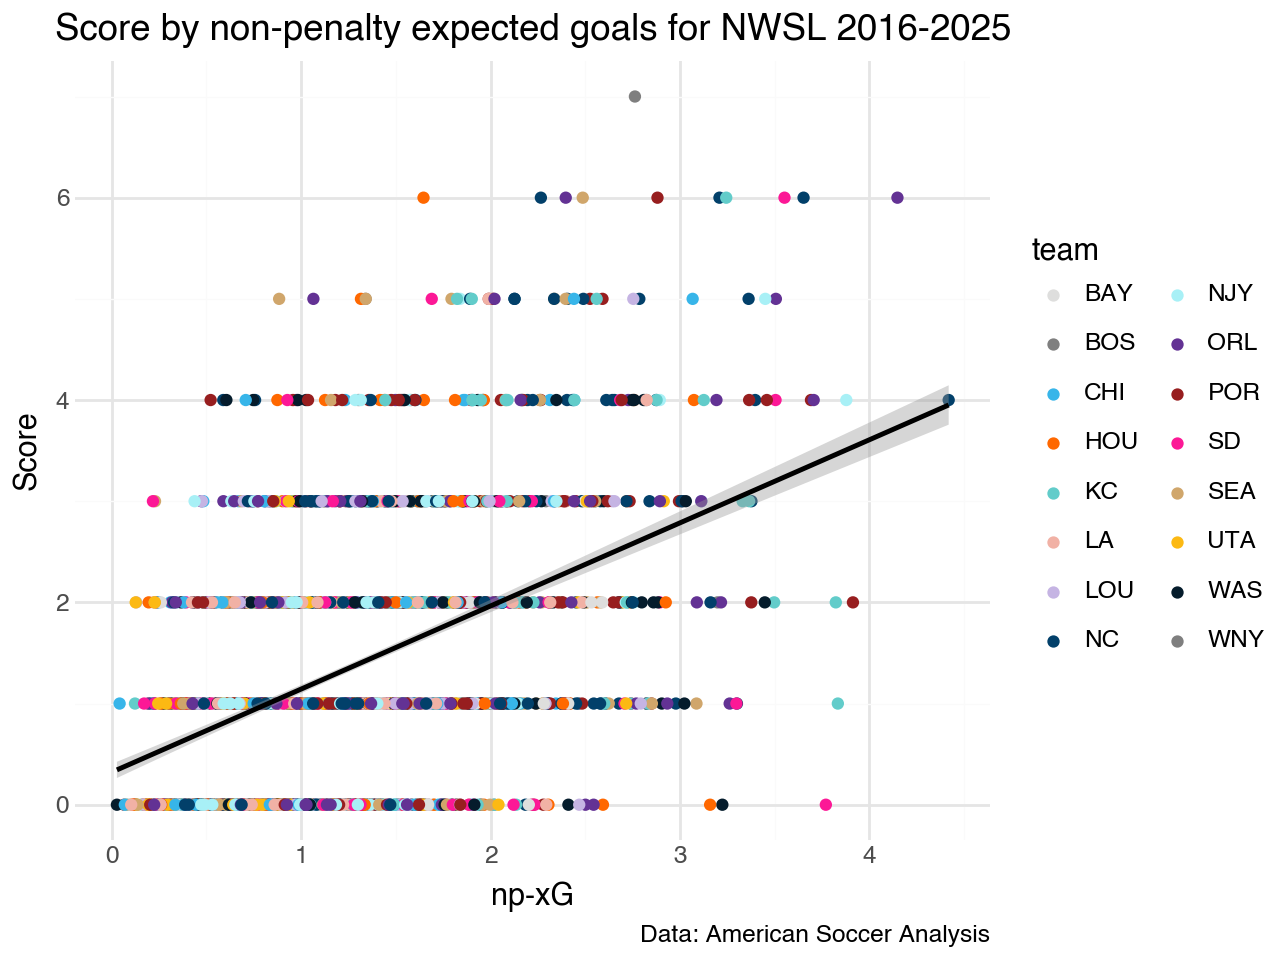

In [12]:
(
    ggplot(nwsl_df, aes(x="xgoals_for", y="score_for"))
    + geom_point(aes(color="team"))
    + scale_color_manual(nwsl_primary_colors)
    + geom_smooth()
    + theme_minimal()
    + labs(
        y="Score",
        x="np-xG",
        title=f"Score by non-penalty expected goals for NWSL {nwsl_df.season_name.min()}-{nwsl_df.season_name.max()}",
        caption="Data: American Soccer Analysis",
    )
)

/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/st

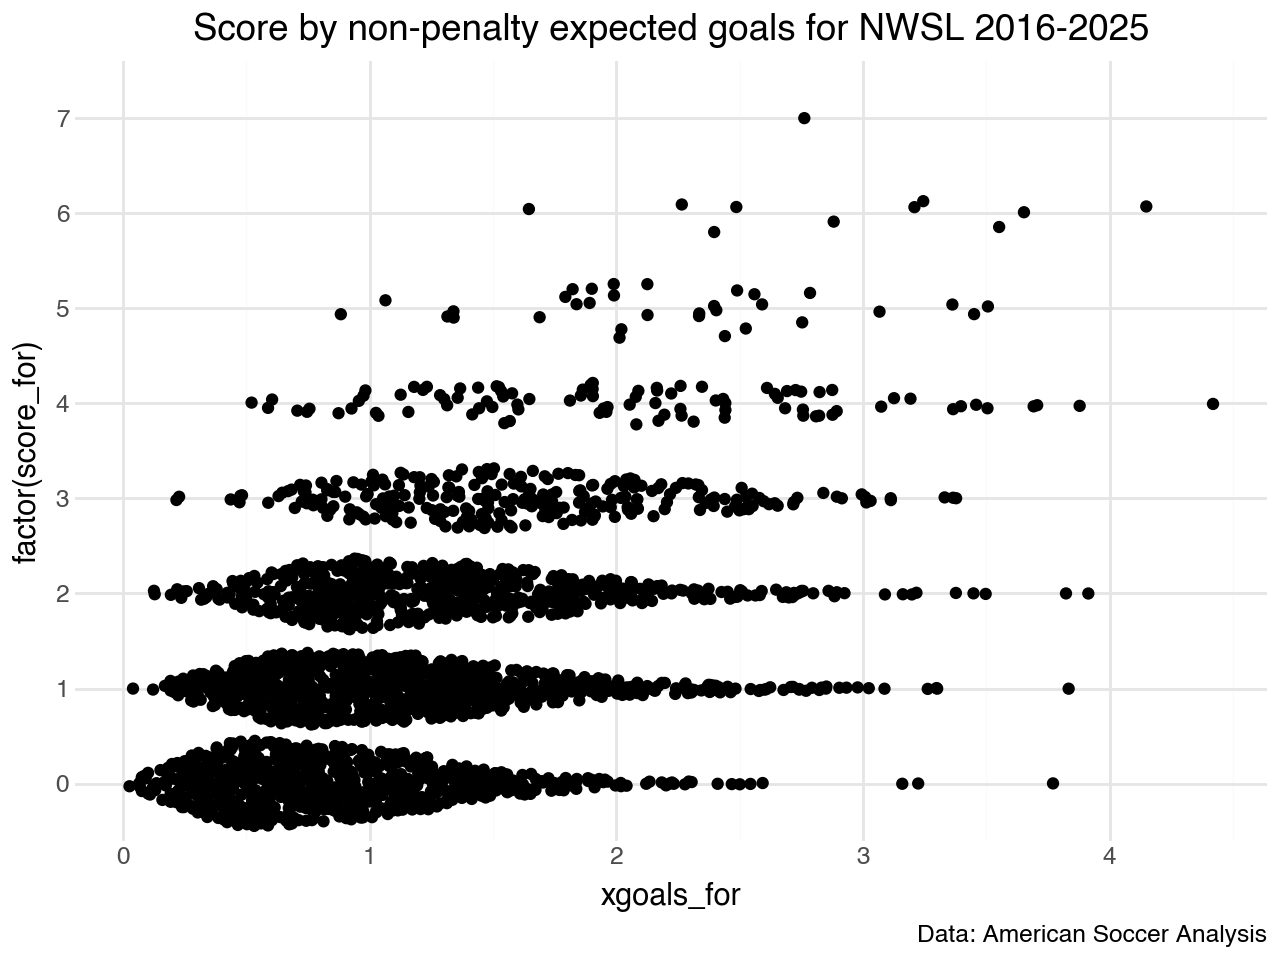

In [13]:
(
    ggplot(nwsl_df, aes(y="xgoals_for", x="factor(score_for)"))
    # + geom_point(aes(color="team"))
    # + geom_violin(style="right")
    # + geom_density_2d(levels=10, n=32)
    + geom_sina()
    + scale_color_manual(nwsl_primary_colors)
    + geom_smooth()
    + theme_minimal()
    + coord_flip()
    + labs(
        # y="Score",
        # x="np-xG",
        title=f"Score by non-penalty expected goals for NWSL {nwsl_df.season_name.min()}-{nwsl_df.season_name.max()}",
        caption="Data: American Soccer Analysis",
    )
)

In [14]:
nwsl_df.xgoals_for.corr(nwsl_df.score_for)

np.float64(0.46303602487519263)

In [15]:
nwsl_df.shots_for.corr(nwsl_df.score_for)

np.float64(0.24924591482868158)

/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/st

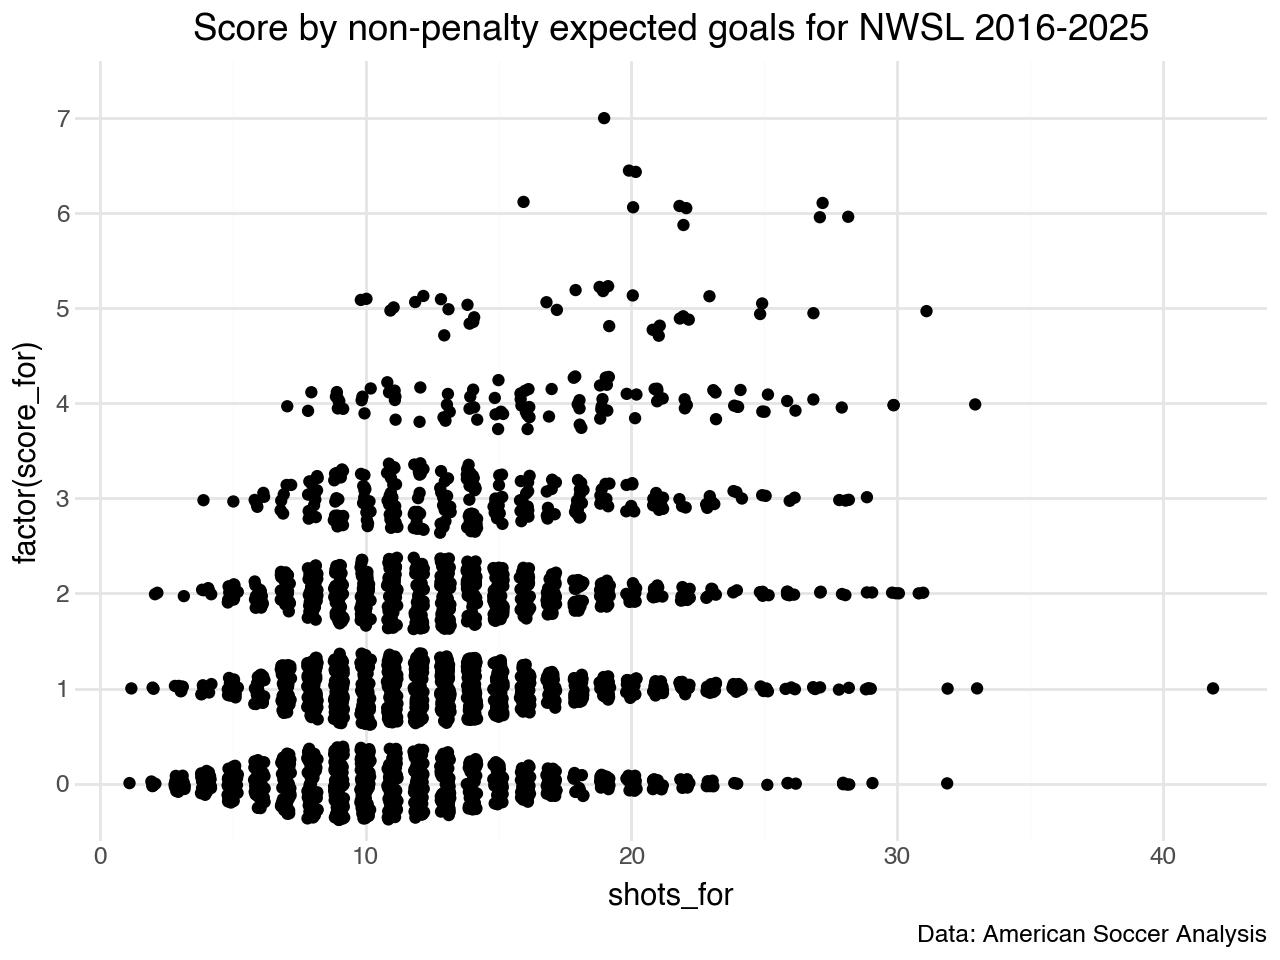

In [16]:
(
    ggplot(nwsl_df, aes(y="shots_for", x="factor(score_for)"))
    # + geom_point(aes(color="team"))
    # + geom_violin(style="right")
    # + geom_density_2d(levels=10, n=32)
    + geom_sina()
    # + scale_color_manual(nwsl_primary_colors)
    + geom_smooth()
    + theme_minimal()
    + coord_flip()
    + labs(
        # y="Score",
        # x="np-xG",
        title=f"Score by non-penalty expected goals for NWSL {nwsl_df.season_name.min()}-{nwsl_df.season_name.max()}",
        caption="Data: American Soccer Analysis",
    )
)

In [36]:
nwsl_df["xgoals_for_bin25"] = (nwsl_df.xgoals_for // 0.25) * 0.25

nwsl_df["xgoals_for_bin25"] = (
    "xg: "
    + nwsl_df["xgoals_for_bin25"].astype(str)
    + "-"
    + (nwsl_df["xgoals_for_bin25"] + 0.25).astype(str)
)

In [37]:
nwsl_df["xgoals_for_bin5"] = (nwsl_df.xgoals_for // 0.5) * 0.5

nwsl_df["xgoals_for_bin5"] = (
    "xg: "
    + nwsl_df["xgoals_for_bin5"].astype(str)
    + "-"
    + (nwsl_df["xgoals_for_bin5"] + 0.5).astype(str)
)

In [38]:
nwsl_df.xgoals_for_bin25.value_counts()

xgoals_for_bin25
xg: 0.75-1.0    433
xg: 0.5-0.75    419
xg: 1.0-1.25    395
xg: 1.25-1.5    349
xg: 0.25-0.5    263
xg: 1.5-1.75    234
xg: 1.75-2.0    180
xg: 2.0-2.25    102
xg: 2.25-2.5     80
xg: 0.0-0.25     58
xg: 2.5-2.75     57
xg: 2.75-3.0     31
xg: 3.0-3.25     19
xg: 3.25-3.5     14
xg: 3.5-3.75      5
xg: 3.75-4.0      5
xg: 4.25-4.5      1
xg: 4.0-4.25      1
Name: count, dtype: int64

In [39]:
nwsl_df.xgoals_for_bin5

0       xg: 1.0-1.5
1       xg: 1.5-2.0
2       xg: 1.0-1.5
3       xg: 0.0-0.5
4       xg: 0.0-0.5
           ...     
2641    xg: 1.0-1.5
2642    xg: 1.0-1.5
2643    xg: 1.0-1.5
2644    xg: 1.0-1.5
2645    xg: 1.5-2.0
Name: xgoals_for_bin5, Length: 2646, dtype: object

In [44]:
nwsl_df["xgoals_for_bin"] = nwsl_df.xgoals_for_bin25
nwsl_df.loc[nwsl_df.xgoals_for >= 2.5, "xgoals_for_bin"] = nwsl_df.loc[
    nwsl_df.xgoals_for >= 2.5, "xgoals_for_bin5"
]
nwsl_df.loc[nwsl_df.xgoals_for >= 3.0, "xgoals_for_bin"] = "xg: 3.0+"

In [45]:
nwsl_df.xgoals_for_bin.value_counts()

xgoals_for_bin
xg: 0.75-1.0    433
xg: 0.5-0.75    419
xg: 1.0-1.25    395
xg: 1.25-1.5    349
xg: 0.25-0.5    263
xg: 1.5-1.75    234
xg: 1.75-2.0    180
xg: 2.0-2.25    102
xg: 2.5-3.0      88
xg: 2.25-2.5     80
xg: 0.0-0.25     58
xg: 3.0+         45
Name: count, dtype: int64

/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/stat_smooth.py:213: PlotnineWarning: Smoothing requires 2 or more points. Got 1. Not enough points for smoothing. If this message a surprise, make sure the column mapped to the x aesthetic has the right dtype.
/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/stats/st

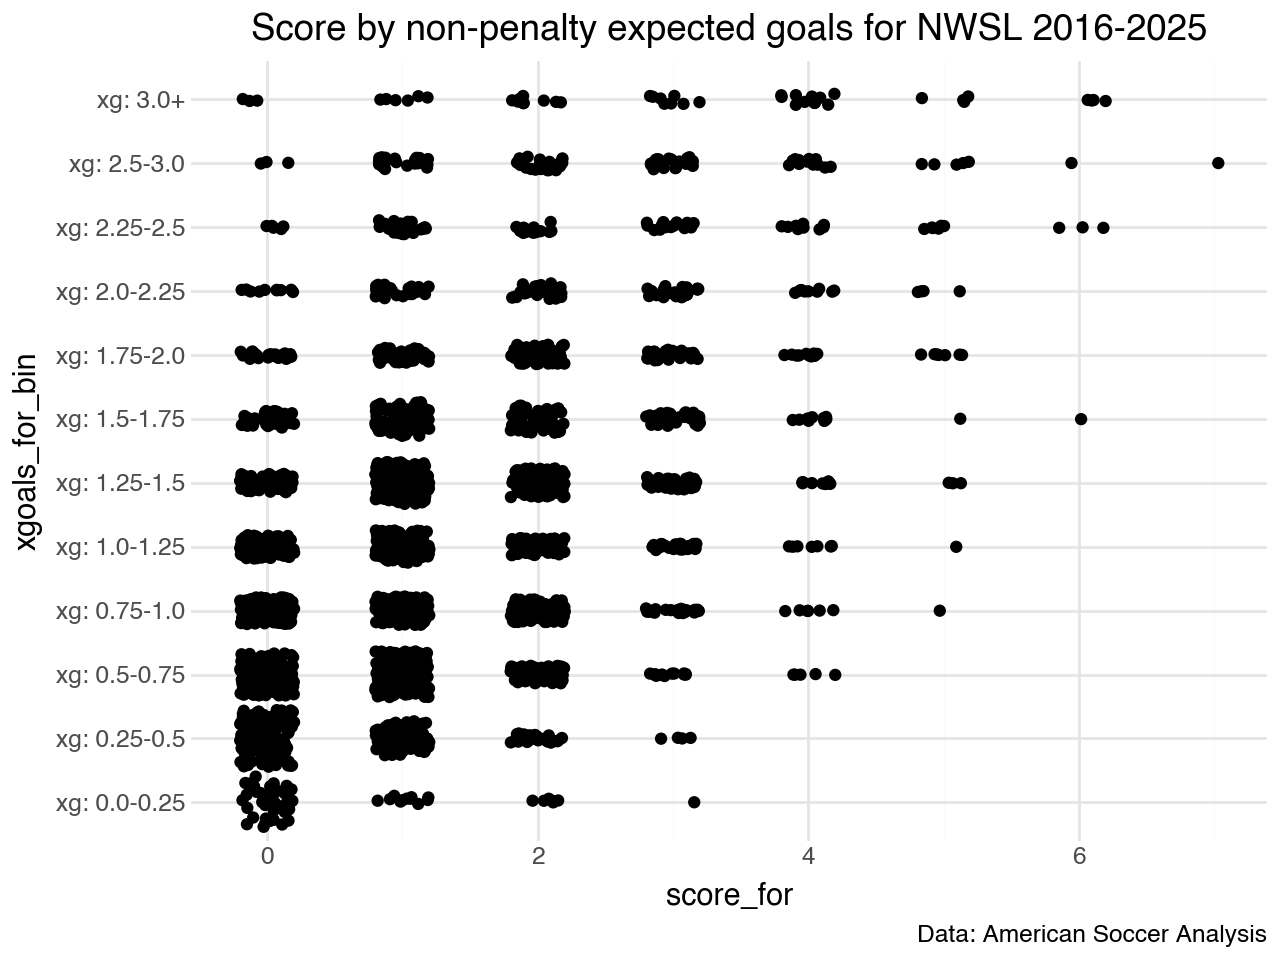

In [46]:
(
    ggplot(nwsl_df, aes(y="score_for", x="xgoals_for_bin"))
    # + geom_point(aes(color="team"))
    # + geom_violin(style="right")
    # + geom_density_2d(levels=10, n=32)
    + geom_sina()
    # + scale_color_manual(nwsl_primary_colors)
    + geom_smooth()
    + theme_minimal()
    + coord_flip()
    + labs(
        # y="Score",
        # x="np-xG",
        title=f"Score by non-penalty expected goals for NWSL {nwsl_df.season_name.min()}-{nwsl_df.season_name.max()}",
        caption="Data: American Soccer Analysis",
    )
)

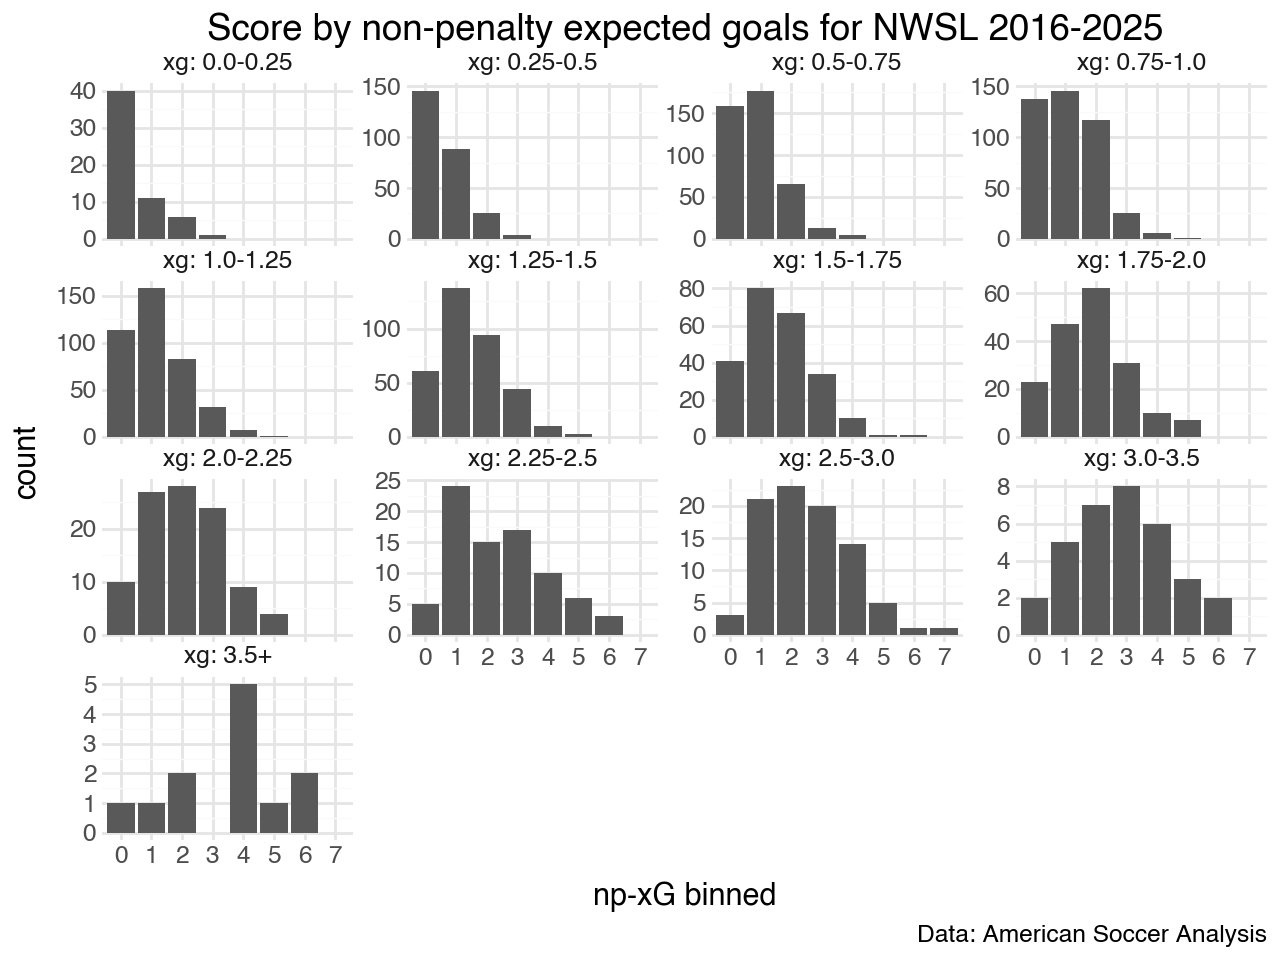

In [23]:
(
    ggplot(nwsl_df, aes(x="factor(score_for)", y=after_stat("count")))
    + geom_bar()
    + facet_wrap("xgoals_for_bin", scales="free_y")
    + theme_minimal()
    + labs(
        x="np-xG binned",
        title=f"Score by non-penalty expected goals for NWSL {nwsl_df.season_name.min()}-{nwsl_df.season_name.max()}",
        caption="Data: American Soccer Analysis",
    )
)

In [24]:
similar_xg_games = decorate_game_ids(
    xg_df.query("(xgoals >= 2.5) & (xgoals <= 2.7)")
).sort_values("team")

similar_xg_games

NameError: name 'xg_df' is not defined

In [ ]:
similar_xg_games.score.value_counts()

score
2    16
3    14
1    13
4     7
0     3
5     1
Name: count, dtype: int64